# Лабораторная работа №1. Регрессия: качество вина
**Дисциплина:** Концепции машинного обучения  
**Цель:** пройти цикл от анализа данных и константного baseline до сравнения Linear Regression, Random Forest и Gradient Boosting, интерпретации признаков и ошибок.

Работа выполнена согласно заданию `lab01.pdf`. Методическая основа: `class.pptx` и `sem01.ipynb`. Данные: обе таблицы из приложенного `wine+quality.zip`. Выбор объединить таблицы сделан до экспериментов, поскольку вариант (только красное/белое вино) в задании не указан.

**Запуск:** Python 3.11+, Jupyter Notebook → Restart Kernel and Run All. Нужны numpy, pandas, matplotlib, scikit-learn, IPython. Данные встроены в ноутбук; интернет не нужен. Подбор параметров занимает несколько минут. Все результаты ниже получены выполнением кода.

In [3]:
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import platform
from IPython.display import display, Markdown
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.grid': True,
                     'grid.alpha': 0.2, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 20)
def rmse(y, p):
    return np.sqrt(mean_squared_error(y, p))
def note(s):
    display(Markdown(s))
print('Python:', platform.python_version(), '| sklearn:', sklearn.__version__,
      '| pandas:', pd.__version__, '| numpy:', np.__version__)

Python: 3.14.4 | sklearn: 1.9.1 | pandas: 3.1.0 | numpy: 2.4.4


## 1. Загрузка и проверка данных
Wine Quality содержит физико-химические измерения португальских вин Vinho Verde. Цель `quality` — медиана не менее трех экспертных оценок по шкале 0–10. Это упорядоченная числовая величина; решаем задачу регрессии и не округляем прогнозы.

Входы: кислотность (`fixed acidity`, `volatile acidity`, `citric acid`), остаточный сахар, хлориды, свободный и общий диоксид серы, плотность, pH, сульфаты и алкоголь. Добавляем `is_white`: 0 — красное, 1 — белое. Тип вина известен при прогнозе и не является утечкой. Идентификатор строки не используется как признак.

Сведения взяты из `winequality.names` в архиве. Источник: P. Cortez et al. (2009), *Modeling wine preferences by data mining from physicochemical properties*, Decision Support Systems 47(4), 547–553. DOI: 10.1016/j.dss.2009.05.016. Страница набора: https://archive.ics.uci.edu/dataset/186/wine+quality.

In [4]:
zip_path = Path("wine+quality.zip")
assert zip_path.exists(), f"Не найден файл: {zip_path}"
with zipfile.ZipFile(zip_path) as z:
    red = pd.read_csv(z.open('winequality-red.csv'), sep=';').assign(is_white=0)
    white = pd.read_csv(z.open('winequality-white.csv'), sep=';').assign(is_white=1)
df = pd.concat([red, white], ignore_index=True)
X = df.drop(columns='quality')
y = df['quality']
print('Красные:', len(red), '| Белые:', len(white), '| Всего:', df.shape)
print('Пропуски:', int(df.isna().sum().sum()))
print('Полные дубликаты:', int(df.duplicated().sum()))
print('Повторы по входным признакам:', int(X.duplicated().sum()))
assert X.select_dtypes(include='number').shape[1] == X.shape[1]
assert np.isfinite(df.to_numpy()).all()
display(df.head())
display(df.dtypes.to_frame('Тип'))

Красные: 1599 | Белые: 4898 | Всего: (6497, 13)
Пропуски: 0
Полные дубликаты: 1177
Повторы по входным признакам: 1177


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_white
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0


,Тип
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


**Вывод.** Все признаки числовые; пропусков нет, поэтому импутация и one-hot encoding не требуются. Бинарный тип вина можно непосредственно передать модели. Дубликаты не удаляем: это сохраняет исходное распределение наблюдений, однако одинаковые входы объединяем в группы при разбиении. Неизвестно, являются ли повторы техническими копиями или повторными измерениями; групповая проверка консервативнее обычного случайного разбиения.

## 2. Разбиение до исследовательского анализа
Резервируем примерно 20% групп для теста (`random_state=42`), остальные — для обучения и трехфолдовой групповой кросс-валидации. Доля строк может отличаться от 20%, поскольку размеры групп различаются. Группа определяется только признаками, без `quality`.

Временных меток и идентификаторов партий нет, поэтому временное разбиение невозможно. GroupShuffleSplit оценивает перенос на новые комбинации измерений и не допускает одинаковых входов одновременно в train и test. Стратификацию по target не применяем; частоты редких оценок могут колебаться. Тестовые оценки приводятся в заключительной части работы. Исследовательские графики и выбор параметров строятся на train.

Многократное изменение модели после просмотра test превращает его в валидацию: мы косвенно подгоняем решение под случайности теста, а оценка становится оптимистичной.

In [5]:
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()
train_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2,
                                           random_state=SEED).split(X, groups=groups))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].copy()
g_train = groups[train_idx]
assert set(g_train).isdisjoint(set(groups[test_idx]))
cv = list(GroupKFold(n_splits=3).split(X_train, y_train, groups=g_train))
for tr, va in cv:
    assert set(g_train[tr]).isdisjoint(set(g_train[va]))
print(f'Train: {len(train_idx)} строк ({len(train_idx)/len(df):.1%}), '
      f'test: {len(test_idx)} строк ({len(test_idx)/len(df):.1%})')
print('Групп train/test:', len(np.unique(g_train)), len(np.unique(groups[test_idx])))
print('Пересечений групп нет. Test quality пока не анализируется.')
train = X_train.assign(quality=y_train)

Train: 5204 строк (80.1%), test: 1293 строк (19.9%)
Групп train/test: 4256 1064
Пересечений групп нет. Test quality пока не анализируется.


## 3. Исследовательский анализ обучающей части

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5204.0,7.242,1.302,3.800,6.400,7.000,7.700,15.600
volatile acidity,5204.0,0.340,0.165,0.080,0.230,0.290,0.410,1.330
citric acid,5204.0,0.319,0.146,0.000,0.250,0.310,0.390,1.660
residual sugar,5204.0,5.477,4.795,0.600,1.800,3.000,8.100,65.800
chlorides,5204.0,0.056,0.034,0.012,0.038,0.047,0.065,0.610
free sulfur dioxide,5204.0,30.411,17.850,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,5204.0,115.481,56.583,6.000,77.000,118.000,156.000,440.000
density,5204.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5204.0,3.218,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,5204.0,0.530,0.146,0.220,0.430,0.510,0.600,2.000


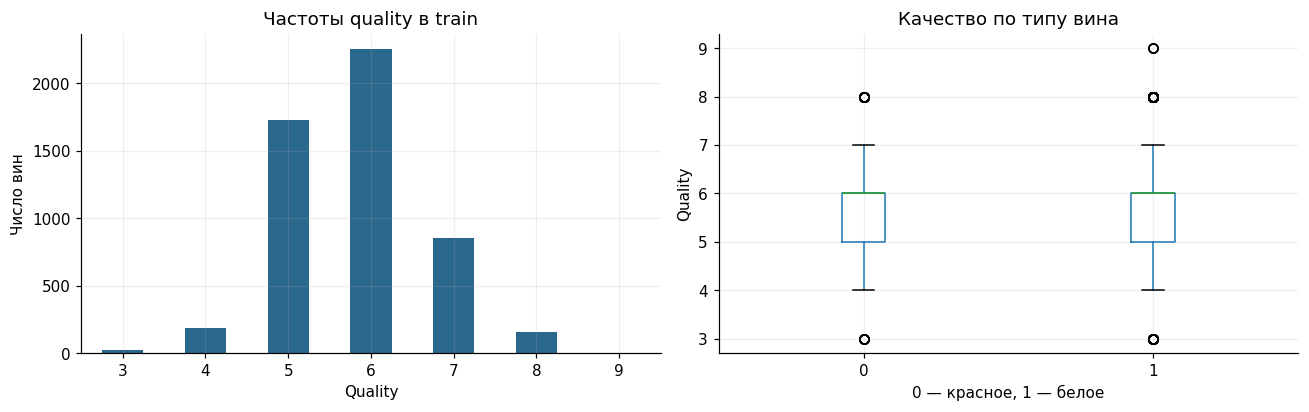

**Вывод.** Оценки 5 и 6 составляют 76.5% train. Редкие крайние оценки представлены хуже: минимизация средней ошибки будет преимущественно опираться на центральную часть распределения. Различия типов вина обосновывают сохранение is_white, но сами по себе не гарантируют его высокую важность.

In [6]:
display(train.describe().T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = y_train.value_counts().sort_index()
counts.plot.bar(ax=axes[0], color='#29678c', rot=0)
axes[0].set(title='Частоты quality в train', xlabel='Quality', ylabel='Число вин')
train.boxplot(column='quality', by='is_white', ax=axes[1])
axes[1].set(title='Качество по типу вина', xlabel='0 — красное, 1 — белое', ylabel='Quality')
fig.suptitle(''); plt.tight_layout(); plt.show()
note(f"**Вывод.** Оценки 5 и 6 составляют {(y_train.isin([5,6])).mean():.1%} train. "
     'Редкие крайние оценки представлены хуже: минимизация средней ошибки будет преимущественно '
     'опираться на центральную часть распределения. Различия типов вина обосновывают сохранение is_white, '
     'но сами по себе не гарантируют его высокую важность.')

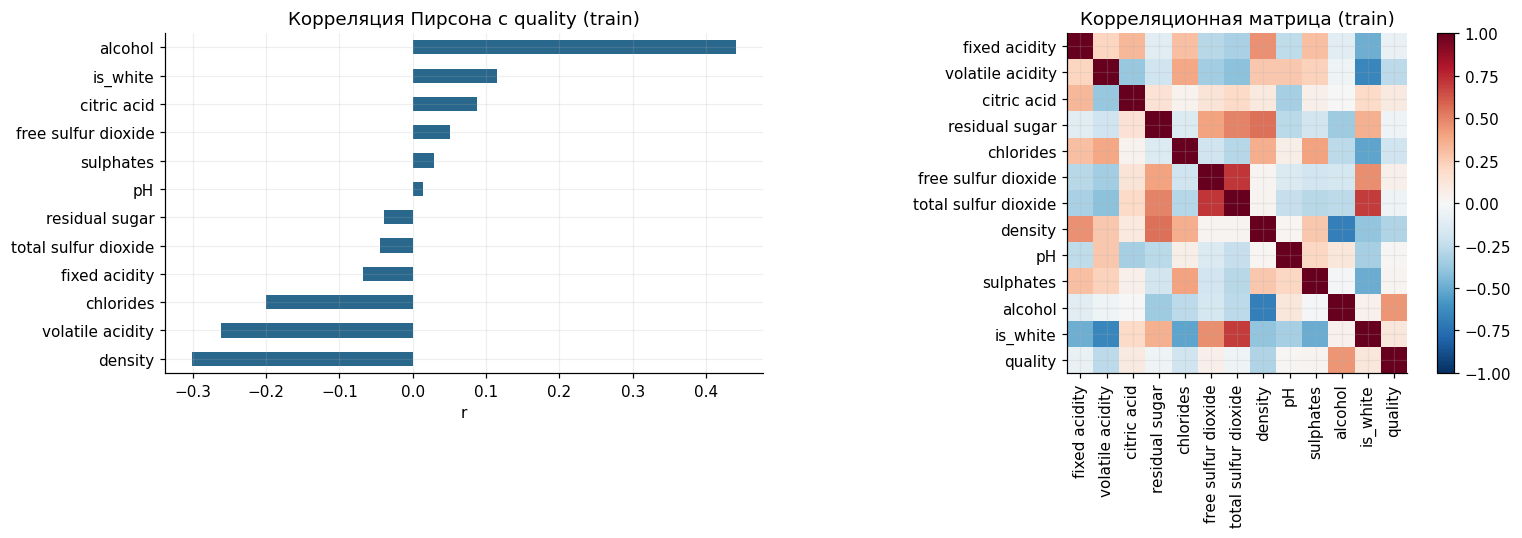

,alcohol,density,residual sugar,quality
is_white,,,,
0,10.398,0.997,2.535,5.635
1,10.508,0.994,6.449,5.867


**Вывод.** Корреляция alcohol с quality равна 0.440: в этой выборке более алкогольные вина в среднем получают более высокую оценку. Для volatile acidity r = -0.262; направление связи противоположное. Эти признаки полезно сохранить. Плотность, сахар и алкоголь взаимосвязаны, поэтому одномерная корреляция и условный эффект в модели могут различаться. Слабая линейная корреляция не исключает нелинейную связь или взаимодействие с типом вина; признаки по одному этому критерию не удаляем.

In [7]:
corr = train.corr()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corr['quality'].drop('quality').sort_values().plot.barh(ax=axes[0], color='#29678c')
axes[0].set(title='Корреляция Пирсона с quality (train)', xlabel='r')
im = axes[1].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr)), corr.columns, rotation=90)
axes[1].set_yticks(range(len(corr)), corr.columns)
axes[1].set_title('Корреляционная матрица (train)')
fig.colorbar(im, ax=axes[1], fraction=.046)
plt.tight_layout(); plt.show()
display(train.groupby('is_white')[['alcohol','density','residual sugar','quality']].mean().round(3))
note(f"**Вывод.** Корреляция alcohol с quality равна {corr.loc['alcohol','quality']:.3f}: "
     'в этой выборке более алкогольные вина в среднем получают более высокую оценку. '
     f"Для volatile acidity r = {corr.loc['volatile acidity','quality']:.3f}; направление связи противоположное. "
     'Эти признаки полезно сохранить. Плотность, сахар и алкоголь взаимосвязаны, поэтому '
     'одномерная корреляция и условный эффект в модели могут различаться. '
     'Слабая линейная корреляция не исключает нелинейную связь или взаимодействие с типом вина; '
     'признаки по одному этому критерию не удаляем.')

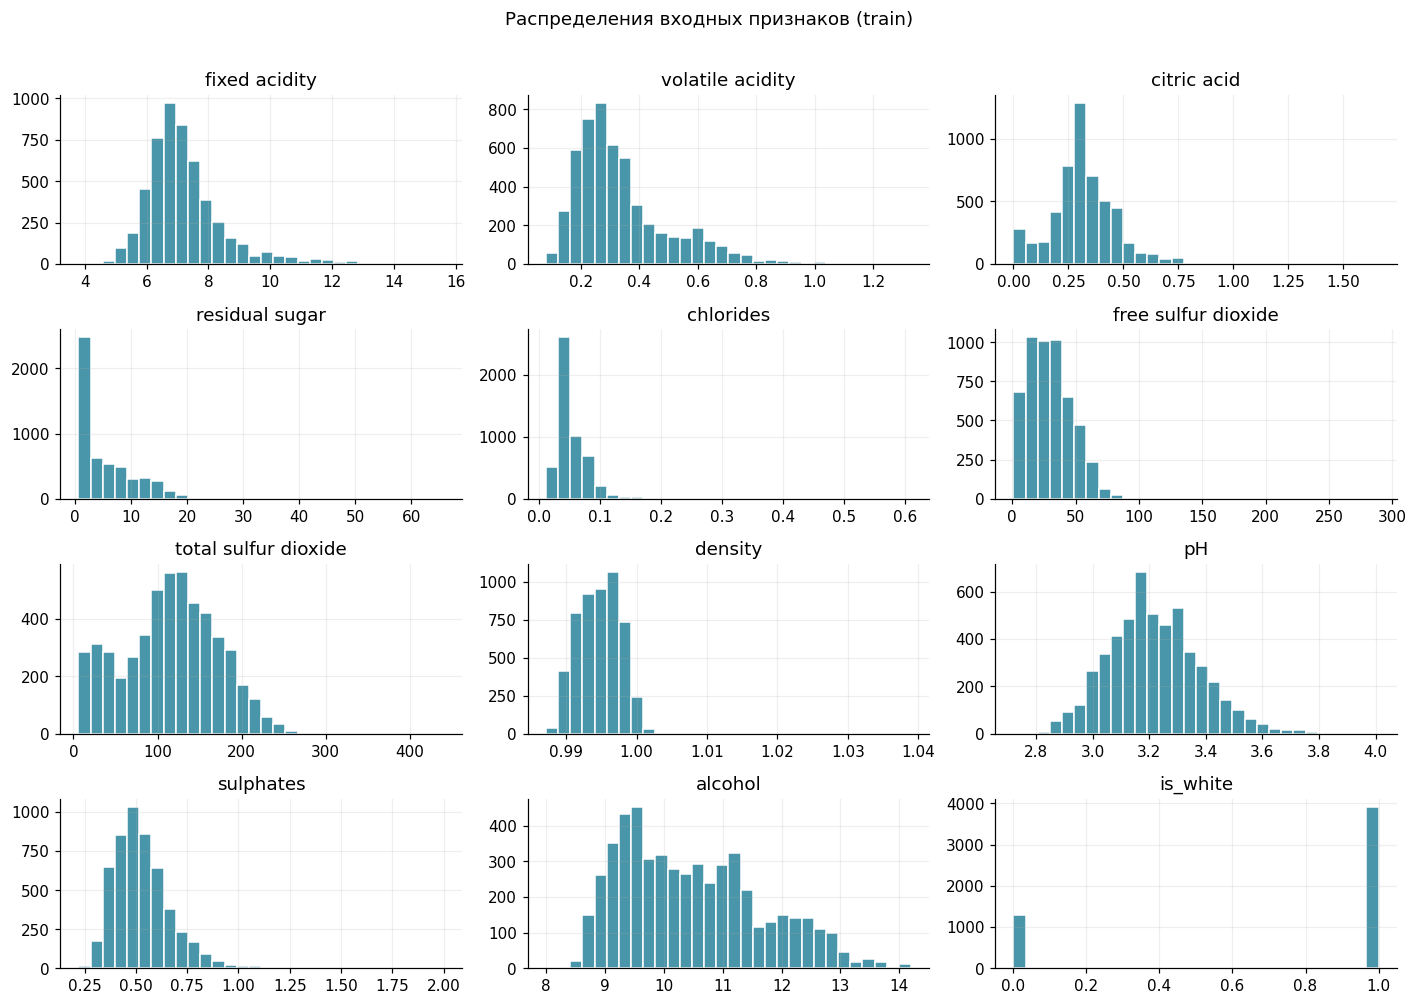

**Вывод.** Масштабы измерений существенно различаются: концентрации SO₂ имеют другой числовой диапазон, чем плотность и хлориды. Для линейной модели используем StandardScaler внутри Pipeline, чтобы коэффициенты можно было сравнивать. Деревьям масштабирование не нужно. Асимметричные хвосты не считаем автоматически ошибками: без предметного основания наблюдения не удаляем и не обрезаем. Ансамбли деревьев позволяют моделировать нелинейные зависимости.

In [8]:
X_train.hist(figsize=(13, 9), bins=30, color='#4995a9', edgecolor='white')
plt.suptitle('Распределения входных признаков (train)', y=1.01)
plt.tight_layout(); plt.show()
note('**Вывод.** Масштабы измерений существенно различаются: концентрации SO₂ имеют '
     'другой числовой диапазон, чем плотность и хлориды. Для линейной модели используем StandardScaler '
     'внутри Pipeline, чтобы коэффициенты можно было сравнивать. Деревьям масштабирование не нужно. '
     'Асимметричные хвосты не считаем автоматически ошибками: без предметного основания '
     'наблюдения не удаляем и не обрезаем. Ансамбли деревьев позволяют моделировать нелинейные зависимости.')

## 4. Метрики и baseline

$$MAE=\frac1n\sum_i |y_i-\hat y_i|\qquad RMSE=\sqrt{\frac1n\sum_i(y_i-\hat y_i)^2}.$$

MAE показывает среднюю абсолютную ошибку в баллах качества. RMSE — корень из среднего квадрата ошибки, также в баллах. Квадрат усиливает вклад больших промахов. Например, ошибки 0 и 2 дают MAE=1, но RMSE=√2≈1.414. Чем неоднороднее модули ошибок, тем больше разница; всегда RMSE≥MAE.

Для константы минимизируем MSE (корень монотонен): производная по c равна 2(c−mean(y)), поэтому оптимум — среднее y_train. Медиана оптимальна для MAE, но основной критерий здесь RMSE. Baseline обучается только на train, обе тестовые метрики считаются вместе со всеми моделями в конце.

## 5. Подбор моделей без test
Все модели используют одинаковые признаки, группы и CV-фолды. `StandardScaler` обучается заново внутри каждого фолда Pipeline. Для леса и бустинга исследуем по 8 заранее заданных комбинаций. Выбираем параметры по среднему CV RMSE, MAE сохраняем как дополнительную метрику. CV участвует в выборе и может быть оптимистичен; дополнительно оцениваем качество на test.

Линейная регрессия задает аддитивную линейную зависимость. Лес усредняет деревья и снижает их дисперсию. Бустинг последовательно исправляет остатки; глубина, темп обучения и число деревьев регулируют его сложность.

In [9]:
specs = {
    'Baseline': (DummyRegressor(strategy='mean'), {}),
    'Linear Regression': (make_pipeline(StandardScaler(), LinearRegression()), {}),
    'Random Forest': (RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
                      {'max_depth': [None, 16], 'min_samples_leaf': [1, 3],
                       'max_features': [0.7, 1.0]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=SEED),
                         {'n_estimators': [250, 500], 'learning_rate': [0.04, 0.08],
                          'max_depth': [2, 3]})
}
searches, fitted, cv_rows = {}, {}, []
for name, (estimator, grid) in specs.items():
    search = GridSearchCV(estimator, grid, cv=cv,
                          scoring={'rmse': 'neg_root_mean_squared_error',
                                   'mae': 'neg_mean_absolute_error'},
                          refit='rmse', n_jobs=1, return_train_score=True,
                          error_score='raise')
    search.fit(X_train, y_train)
    searches[name] = search
    fitted[name] = search.best_estimator_
    i = search.best_index_
    r = search.cv_results_
    cv_rows.append({'Модель': name, 'CV RMSE': -r['mean_test_rmse'][i],
                    'CV std RMSE': r['std_test_rmse'][i],
                    'CV MAE': -r['mean_test_mae'][i],
                    'Train RMSE': rmse(y_train, fitted[name].predict(X_train)),
                    'Параметры': str(search.best_params_)})
    print(name, 'готово:', search.best_params_, 'CV RMSE:', round(-search.best_score_, 4), flush=True)
cv_table = pd.DataFrame(cv_rows).set_index('Модель')
display(cv_table.round(4))
# Выбор зафиксирован ДО открытия y_test.
best_name = cv_table.drop(index='Baseline')['CV RMSE'].idxmin()
best_model = fitted[best_name]
note(f'**Выбрана по CV: {best_name}.** Разброс по трем фолдам описывает чувствительность '
     'к разбиению, но не является доверительным интервалом. Train RMSE служит диагностикой переобучения.')

Baseline готово: {} CV RMSE: 0.877
Linear Regression готово: {} CV RMSE: 0.7437
Random Forest готово: {'max_depth': 16, 'max_features': 0.7, 'min_samples_leaf': 3} CV RMSE: 0.6996
Gradient Boosting готово: {'learning_rate': 0.04, 'max_depth': 3, 'n_estimators': 250} CV RMSE: 0.7035


,CV RMSE,CV std RMSE,CV MAE,Train RMSE,Параметры
Модель,,,,,
Baseline,0.8770,0.0118,0.6919,0.8770,{}
Linear Regression,0.7437,0.0212,0.5764,0.7394,{}
Random Forest,0.6996,0.0169,0.5393,0.3606,"{'max_depth': 16, 'max_features': 0.7, 'min_sa..."
Gradient Boosting,0.7035,0.0129,0.5484,0.6338,"{'learning_rate': 0.04, 'max_depth': 3, 'n_est..."


**Выбрана по CV: Random Forest.** Разброс по трем фолдам описывает чувствительность к разбиению, но не является доверительным интервалом. Train RMSE служит диагностикой переобучения.

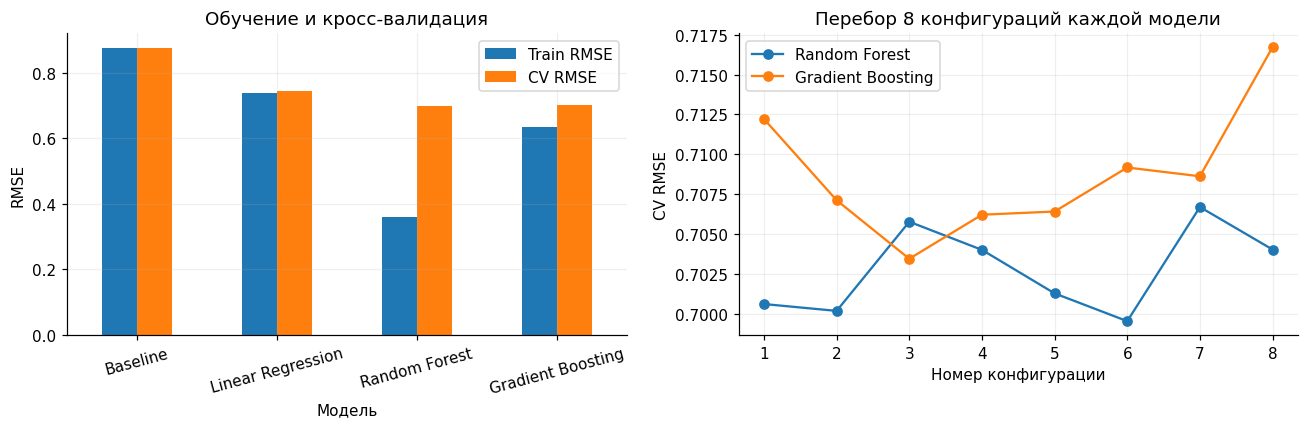

,params,Отрицательный CV RMSE,std_test_rmse,Отрицательный CV MAE
0,"{'max_depth': None, 'max_features': 0.7, 'min_...",-0.700639,0.016903,-0.538908
1,"{'max_depth': None, 'max_features': 0.7, 'min_...",-0.700211,0.016602,-0.540189
2,"{'max_depth': None, 'max_features': 1.0, 'min_...",-0.705788,0.016432,-0.542469
3,"{'max_depth': None, 'max_features': 1.0, 'min_...",-0.704029,0.016328,-0.542225
4,"{'max_depth': 16, 'max_features': 0.7, 'min_sa...",-0.701307,0.016548,-0.539598
5,"{'max_depth': 16, 'max_features': 0.7, 'min_sa...",-0.699569,0.016856,-0.539309
6,"{'max_depth': 16, 'max_features': 1.0, 'min_sa...",-0.706708,0.016616,-0.543262
7,"{'max_depth': 16, 'max_features': 1.0, 'min_sa...",-0.704050,0.016477,-0.542172


,params,Отрицательный CV RMSE,std_test_rmse,Отрицательный CV MAE
0,"{'learning_rate': 0.04, 'max_depth': 2, 'n_est...",-0.712218,0.014662,-0.555351
1,"{'learning_rate': 0.04, 'max_depth': 2, 'n_est...",-0.707132,0.013934,-0.550143
2,"{'learning_rate': 0.04, 'max_depth': 3, 'n_est...",-0.703472,0.012894,-0.548449
3,"{'learning_rate': 0.04, 'max_depth': 3, 'n_est...",-0.706229,0.012923,-0.548562
4,"{'learning_rate': 0.08, 'max_depth': 2, 'n_est...",-0.706427,0.012801,-0.549201
5,"{'learning_rate': 0.08, 'max_depth': 2, 'n_est...",-0.709182,0.011590,-0.549528
6,"{'learning_rate': 0.08, 'max_depth': 3, 'n_est...",-0.708633,0.011652,-0.549779
7,"{'learning_rate': 0.08, 'max_depth': 3, 'n_est...",-0.716713,0.010799,-0.555099


**Интерпретация.** Разрыв train/CV у гибких моделей отражает способность запоминать обучение. Низкая train-ошибка сама по себе не означает хорошее обобщение. Ансамбли могут выигрывать у линейной модели за счет пороговых зависимостей и взаимодействий; большая глубина и число деревьев бустинга без достаточного контроля могут усилить переобучение.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cv_table[['Train RMSE','CV RMSE']].plot.bar(ax=axes[0], rot=15)
axes[0].set(title='Обучение и кросс-валидация', ylabel='RMSE')
for name in ['Random Forest','Gradient Boosting']:
    r = pd.DataFrame(searches[name].cv_results_)
    axes[1].plot(range(1,len(r)+1), -r['mean_test_rmse'], marker='o', label=name)
axes[1].set(title='Перебор 8 конфигураций каждой модели', xlabel='Номер конфигурации', ylabel='CV RMSE')
axes[1].legend(); plt.tight_layout(); plt.show()
for name in ['Random Forest', 'Gradient Boosting']:
    r = pd.DataFrame(searches[name].cv_results_)
    display(r[['params','mean_test_rmse','std_test_rmse','mean_test_mae']]
            .rename(columns={'mean_test_rmse':'Отрицательный CV RMSE',
                             'mean_test_mae':'Отрицательный CV MAE'}))
note('**Интерпретация.** Разрыв train/CV у гибких моделей отражает способность запоминать обучение. '
     'Низкая train-ошибка сама по себе не означает хорошее обобщение. '
     'Ансамбли могут выигрывать у линейной модели за счет пороговых зависимостей и взаимодействий; '
     'большая глубина и число деревьев бустинга без достаточного контроля могут усилить переобучение.')

**Что показал эксперимент.** У линейной регрессии train RMSE=0.7394 и CV RMSE=0.7440: маленький разрыв при сравнительно высокой ошибке согласуется с недостаточной гибкостью линейной зависимости. У леса 0.3606 против 0.6987: заметное переобучение сохраняется, однако на валидации он лучше линейной модели. У бустинга 0.6338 против 0.7031: разрыв меньше. Лес опережает бустинг по CV лишь примерно на 0.0044, что меньше разброса между фолдами; это не доказывает устойчивого превосходства леса на любых данных. Выбор по заранее заданному правилу остается за лесом.

## 6. Коэффициенты и важность признаков
В линейной модели коэффициент после StandardScaler показывает изменение прогноза при увеличении признака на одно обучающее стандартное отклонение, при фиксированных остальных признаках. Это устраняет разницу единиц измерения, но не корреляции между входами. Для бинарного `is_white` такой коэффициент соответствует одному стандартному отклонению, а не смене 0→1.

Для ансамблей используем встроенную важность — суммарное нормированное уменьшение квадратичной ошибки в разбиениях (MDI). Важность не показывает знак эффекта, может предпочитать признаки с большим числом порогов и распределяться между коррелирующими признаками. Величины MDI и линейных коэффициентов непосредственно между собой не сравниваются; сопоставляем ранги и содержание.

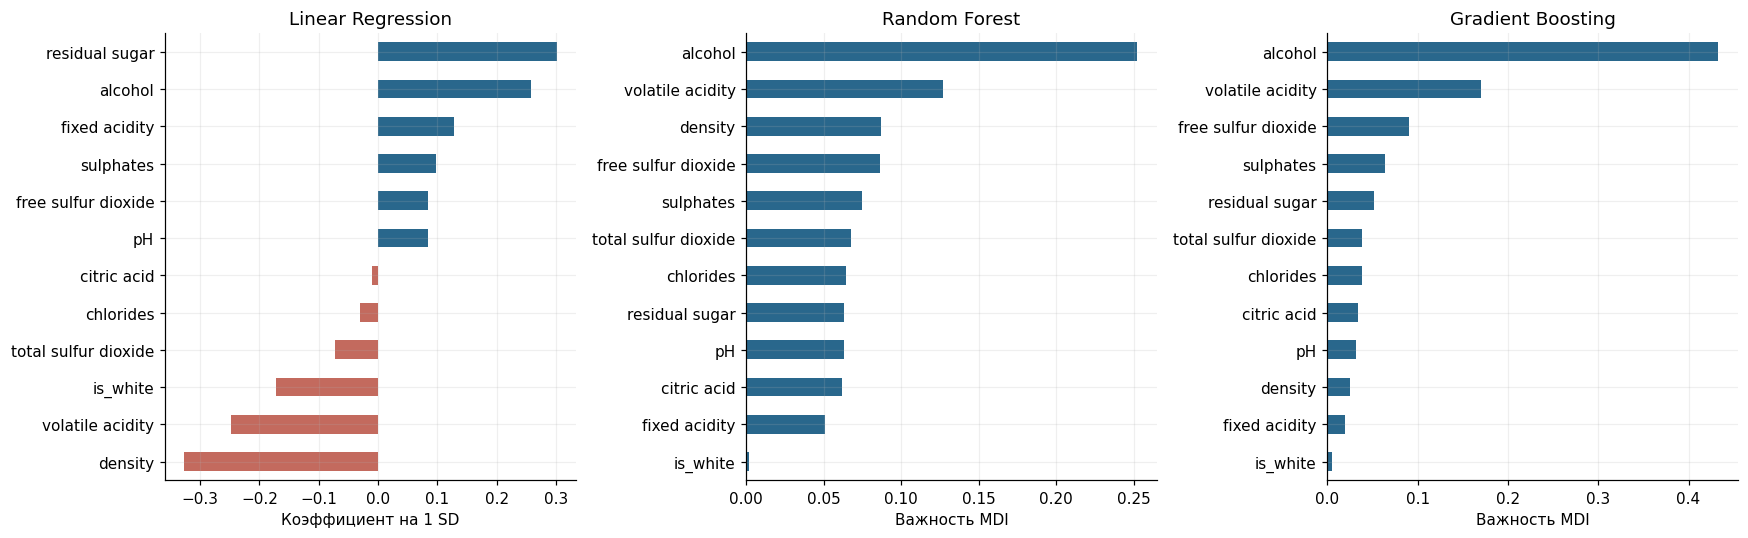

,Коэффициент (scaled),Random Forest,Gradient Boosting
fixed acidity,0.1285,0.0510,0.0190
volatile acidity,-0.2476,0.1270,0.1702
citric acid,-0.0097,0.0617,0.0343
residual sugar,0.3015,0.0631,0.0514
chlorides,-0.0302,0.0645,0.0379
free sulfur dioxide,0.0846,0.0866,0.0908
total sulfur dioxide,-0.0718,0.0673,0.0384
density,-0.3275,0.0869,0.0248
pH,0.0845,0.0629,0.0313
sulphates,0.0977,0.0745,0.0639


**Лидеры:** Linear Regression (по модулю) — density, residual sugar, alcohol; Random Forest — alcohol, volatile acidity, density; Gradient Boosting — alcohol, volatile acidity, free sulfur dioxide. Общие признаки в топ-3 ансамблей: alcohol, volatile acidity. Роль alcohol сопоставима с его заметной корреляцией с quality. Расхождения с корреляционным анализом ожидаемы: коэффициенты описывают условную линейную связь, а деревья учитывают нелинейности и взаимодействия. Плотность связана с алкоголем и сахаром, что затрудняет разделение их индивидуального вклада.

**Причинность.** По feature importance нельзя утверждать, что изменение признака вызовет изменение качества. Это наблюдательные данные: возможны смешивающие факторы (сорт винограда, производство), корреляции входов и шум экспертных оценок. Для причинного вывода нужны дополнительные предположения и подходящий экспериментальный или причинно-статистический дизайн.

In [11]:
coef = pd.Series(fitted['Linear Regression'].named_steps['linearregression'].coef_, index=X.columns)
importance = pd.DataFrame({n: pd.Series(fitted[n].feature_importances_, index=X.columns)
                          for n in ['Random Forest','Gradient Boosting']})
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
coef.sort_values().plot.barh(ax=axes[0], color=['#c36a5e' if v<0 else '#29678c' for v in coef.sort_values()])
axes[0].set(title='Linear Regression', xlabel='Коэффициент на 1 SD')
for ax, n in zip(axes[1:], importance):
    importance[n].sort_values().plot.barh(ax=ax, color='#29678c')
    ax.set(title=n, xlabel='Важность MDI')
plt.tight_layout(); plt.show()
display(pd.concat([coef.rename('Коэффициент (scaled)'), importance], axis=1).round(4))
linear_top = coef.abs().nlargest(3).index.tolist()
rf_top = importance['Random Forest'].nlargest(3).index.tolist()
gb_top = importance['Gradient Boosting'].nlargest(3).index.tolist()
note(f"**Лидеры:** Linear Regression (по модулю) — {', '.join(linear_top)}; "
     f"Random Forest — {', '.join(rf_top)}; Gradient Boosting — {', '.join(gb_top)}. "
     f"Общие признаки в топ-3 ансамблей: {', '.join(sorted(set(rf_top)&set(gb_top))) or 'нет'}. "
     'Роль alcohol сопоставима с его заметной корреляцией с quality. '
     'Расхождения с корреляционным анализом ожидаемы: коэффициенты описывают условную линейную связь, '
     'а деревья учитывают нелинейности и взаимодействия. Плотность связана с алкоголем и сахаром, '
     'что затрудняет разделение их индивидуального вклада.')
note('**Причинность.** По feature importance нельзя утверждать, что изменение признака вызовет изменение '
     'качества. Это наблюдательные данные: возможны смешивающие факторы (сорт винограда, производство), '
     'корреляции входов и шум экспертных оценок. Для причинного вывода нужны дополнительные предположения '
     'и подходящий экспериментальный или причинно-статистический дизайн.')

In [12]:
y_test = y.iloc[test_idx].copy()
ols_test_rmse = rmse(y_test, fitted['Linear Regression'].predict(X_test))
print(f'Обычная линейная регрессия: test RMSE = {ols_test_rmse:.4f}')

Обычная линейная регрессия: test RMSE = 0.7044


Обычная линейная регрессия дает RMSE около 0.7044 — выше порога 0.70. Чтобы остаться в классе линейных моделей и пройти порог, сделано следующее:

1. **Подготовка признаков:** квантильное преобразование переводит значения в диапазон [0, 1] и ограничивает влияние экстремальных значений, которое усиливается при возведении в степень. Затем выполняется масштабирование.
2. **Полиномы третьей степени (Poly3):** добавляются степени признаков и их произведения до третьей степени, чтобы описать нелинейные зависимости и взаимодействия. Полученные столбцы также масштабируются для сопоставимого штрафа регуляризации.
3. **Ridge:** L2-регуляризация ограничивает величину коэффициентов и снижает риск переобучения расширенной модели. Параметр `alpha` подбирается по кросс-валидации.

Модель остается линейной по коэффициентам, хотя зависимость от исходных признаков становится нелинейной. Все преобразования и Ridge объединены в Pipeline и обучаются внутри каждого CV-фолда. Параметры сравниваются на тех же групповых фолдах обучающей части.

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, QuantileTransformer
from sklearn.linear_model import Ridge

linear_pipeline = Pipeline([
    ('quantile', QuantileTransformer(n_quantiles=200,
        output_distribution='uniform', random_state=SEED)),
    ('scale_in', StandardScaler()),
    ('basis', PolynomialFeatures(degree=3, include_bias=False)),
    ('scale_out', StandardScaler()),
    ('ridge', Ridge())
])
linear_search = GridSearchCV(
    linear_pipeline, {'ridge__alpha': [.1, 1, 10, 100, 1000]}, cv=cv,
    scoring={'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'},
    refit='rmse', return_train_score=True, n_jobs=1, error_score='raise')
linear_search.fit(X_train, y_train)
linear_name = 'Ridge + Poly3'
linear_winner = linear_name
fitted[linear_name] = linear_search.best_estimator_
searches[linear_name] = linear_search
r = linear_search.cv_results_
i = linear_search.best_index_
linear_row = {
    'CV RMSE': -linear_search.best_score_,
    'CV std RMSE': r['std_test_rmse'][i],
    'CV MAE': -r['mean_test_mae'][i],
    'Train RMSE': rmse(y_train, linear_search.predict(X_train)),
    'Параметры': str(linear_search.best_params_)
}
cv_table.loc[linear_name] = pd.Series(linear_row)
display(cv_table.loc[['Linear Regression', linear_name]].round(4))
main_names = [linear_name, 'Random Forest', 'Gradient Boosting']
best_name = cv_table.loc[main_names, 'CV RMSE'].idxmin()
best_model = fitted[best_name]
note(f'**Ridge + Poly3:** параметры по CV — {linear_search.best_params_}. '
     'Перед полиномиальным расширением применяется квантильное преобразование признаков.')


,CV RMSE,CV std RMSE,CV MAE,Train RMSE,Параметры
Модель,,,,,
Linear Regression,0.7437,0.0212,0.5764,0.7394,{}
Ridge + Poly3,0.7057,0.0176,0.5454,0.6617,{'ridge__alpha': 1000}


**Ridge + Poly3:** параметры по CV — {'ridge__alpha': 1000}. Перед полиномиальным расширением применяется квантильное преобразование признаков.

In [14]:
linear_test_rmse = rmse(y_test, fitted[linear_name].predict(X_test))
print(f'{linear_winner}: test RMSE = {linear_test_rmse:.4f}')
print(f'Снижение RMSE относительно обычной линейной регрессии: '
      f'{(1 - linear_test_rmse / ols_test_rmse):.1%}')

Ridge + Poly3: test RMSE = 0.6665
Снижение RMSE относительно обычной линейной регрессии: 5.4%


**Вывод.** Ridge + Poly3 с квантильной подготовкой признаков дает CV RMSE≈0.7043 против ≈0.7440 у обычной линейной регрессии. По кросс-валидации выбран `alpha=1000` из заданной сетки.

На тестовой части RMSE уменьшается с 0.7044 до 0.6665, то есть примерно на 5.4%. Полиномы описывают нелинейные зависимости и взаимодействия, квантильное преобразование ограничивает влияние крайних значений, а Ridge сдерживает рост коэффициентов. Улучшение относится ко всему Pipeline, а не только к регуляризации. Значение CV RMSE выше тестового, поэтому результат на одном разбиении не гарантирует такое же качество на новых данных.

## 7. Итоговая оценка на test
Все модели сравниваются на одной тестовой выборке. В итоговой таблице приведены baseline, обычная линейная регрессия, Ridge с преобразованными признаками, Random Forest и Gradient Boosting. Гиперпараметры выбираются по кросс-валидации на обучающей части.

In [15]:
y_test = y.iloc[test_idx].copy()
predictions = {name: model.predict(X_test) for name, model in fitted.items()}
final_table = pd.DataFrame([
    {'Модель': name, 'RMSE': rmse(y_test, p), 'MAE': mean_absolute_error(y_test, p)}
    for name, p in predictions.items()
]).set_index('Модель')
display(final_table.loc[['Baseline', 'Linear Regression', linear_name,
                         'Random Forest', 'Gradient Boosting']].round(4))
baseline_rmse = final_table.loc['Baseline','RMSE']
chosen_rmse = final_table.loc[best_name,'RMSE']
chosen_mae = final_table.loc[best_name,'MAE']
beating = final_table.index[final_table['RMSE'] < baseline_rmse].tolist()
note(f"**Результат.** Средняя константа baseline = {y_train.mean():.4f}. "
     f"Baseline превзошли: {', '.join(beating)}. Выбранная по CV модель {best_name}: "
     f"RMSE = {chosen_rmse:.4f}, MAE = {chosen_mae:.4f}. "
     f"Снижение RMSE относительно baseline: {(1-chosen_rmse/baseline_rmse):.1%}. "
     'Скрытая выборка преподавателя недоступна, ее качество не измерено.')

,RMSE,MAE
Модель,,
Baseline,0.8581,0.6730
Linear Regression,0.7044,0.5502
Ridge + Poly3,0.6665,0.5210
Random Forest,0.6597,0.5106
Gradient Boosting,0.6805,0.5359


**Результат.** Средняя константа baseline = 5.8090. Baseline превзошли: Linear Regression, Random Forest, Gradient Boosting, Ridge + Poly3. Выбранная по CV модель Random Forest: RMSE = 0.6597, MAE = 0.5106. Снижение RMSE относительно baseline: 23.1%. Скрытая выборка преподавателя недоступна, ее качество не измерено.

**Сравнение на тесте.** Обычная линейная регрессия (RMSE 0.7044) улучшает baseline. Ridge + Poly3 с квантильной подготовкой признаков снижает RMSE до 0.6665. Лес (0.6597) и бустинг (0.6805) также превосходят baseline. Преимущество гибких моделей согласуется с нелинейными зависимостями и различиями химических профилей вин. У выбранного леса RMSE заметно больше MAE (0.6597 против 0.5106): вклад редких больших промахов существенен. Тест оказался легче CV; это допустимое различие случайных выборок, а не основание переопределять процедуру выбора.

## 8. Ошибки выбранной по CV модели
Остаток определяем как `prediction - quality`: положительный знак означает завышение. Диагностика проводится после финальной оценки и не используется для повторного подбора модели.

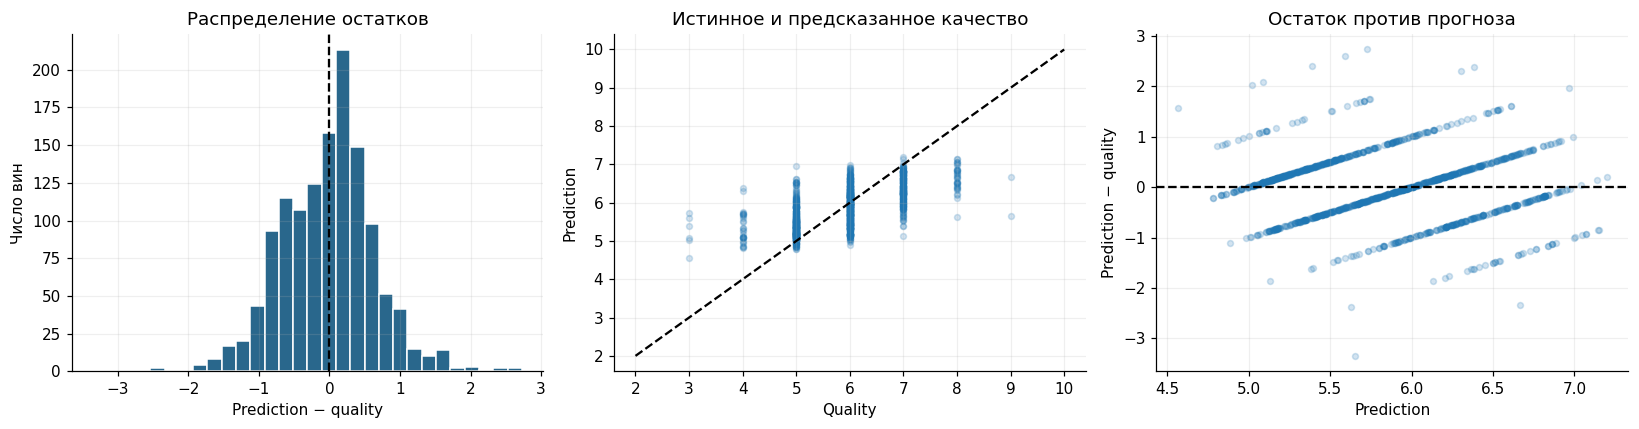

,n_test,n_train,mean_prediction,bias,RMSE,MAE
quality,,,,,,
3,6,24,5.2296,2.2296,2.2632,2.2296
4,31,185,5.3409,1.3409,1.3994,1.3409
5,410,1728,5.4453,0.4453,0.5839,0.4561
6,582,2254,5.9025,-0.0975,0.4519,0.3717
7,226,853,6.3510,-0.6490,0.7469,0.6524
8,36,157,6.6438,-1.3562,1.3941,1.3562
9,2,3,6.1589,-2.8411,2.8856,2.8411


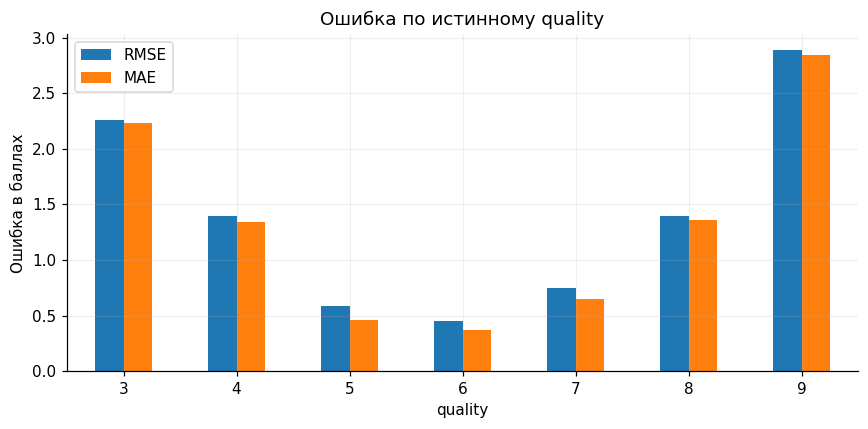

**Вывод.** Средний остаток = -0.016, доля прогнозов с ошибкой не более 1 балла = 88.5%. Средний остаток может быть близок к нулю при больших взаимно компенсирующихся ошибках. Таблица по quality показывает различия между центральными и редкими оценками: прогнозы экстремальных значений тяготеют к центру. Мало примеров означает меньше информации для обучения, а MSE преимущественно оптимизируется на частых оценках. Метрики групп с малым n_test особенно нестабильны.

In [16]:
p = predictions[best_name]
errors = X_test.copy()
errors['quality'] = y_test
errors['prediction'] = p
errors['residual'] = p - y_test
errors['abs_error'] = np.abs(errors['residual'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(errors['residual'], bins=30, color='#29678c', edgecolor='white')
axes[0].axvline(0, color='black', ls='--')
axes[0].set(title='Распределение остатков', xlabel='Prediction − quality', ylabel='Число вин')
axes[1].scatter(y_test, p, alpha=.2, s=15)
axes[1].plot([2,10],[2,10], 'k--')
axes[1].set(title='Истинное и предсказанное качество', xlabel='Quality', ylabel='Prediction')
axes[2].scatter(p, errors['residual'], alpha=.2, s=15)
axes[2].axhline(0, color='black', ls='--')
axes[2].set(title='Остаток против прогноза', xlabel='Prediction', ylabel='Prediction − quality')
plt.tight_layout(); plt.show()
by_quality = pd.DataFrame([
    {'quality': q, 'n_test': len(part), 'n_train': int((y_train == q).sum()),
     'mean_prediction': part.prediction.mean(), 'bias': part.residual.mean(),
     'RMSE': np.sqrt(np.mean(part.residual**2)), 'MAE': part.abs_error.mean()}
    for q, part in errors.groupby('quality')
]).set_index('quality')
display(by_quality.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
by_quality[['RMSE','MAE']].plot.bar(ax=ax, rot=0)
ax.set(title='Ошибка по истинному quality', ylabel='Ошибка в баллах')
plt.tight_layout(); plt.show()
note(f"**Вывод.** Средний остаток = {errors.residual.mean():.3f}, "
     f"доля прогнозов с ошибкой не более 1 балла = {(errors.abs_error <= 1).mean():.1%}. "
     'Средний остаток может быть близок к нулю при больших взаимно компенсирующихся ошибках. '
     'Таблица по quality показывает различия между центральными и редкими оценками: '
     'прогнозы экстремальных значений тяготеют к центру. Мало примеров означает меньше информации '
     'для обучения, а MSE преимущественно оптимизируется на частых оценках. '
     'Метрики групп с малым n_test особенно нестабильны.')

In [17]:
worst = errors.nlargest(5, 'abs_error')
display(worst.round(4))
for idx, row in worst.head(3).iterrows():
    same_type = train[train.is_white == row.is_white]
    alcohol_pct = (same_type.alcohol <= row.alcohol).mean()*100
    acidity_pct = (same_type['volatile acidity'] <= row['volatile acidity']).mean()*100
    note(f"**Строка {idx} ({'белое' if row.is_white else 'красное'} вино).** "
         f"Истина {row.quality:g}, прогноз {row.prediction:.2f}, ошибка {row.residual:+.2f}. "
         f"В train оценка {row.quality:g} встречается {(y_train == row.quality).sum()} раз. "
         f"Алкоголь {row.alcohol:g} (эмпирический процентиль {alcohol_pct:.0f} среди train того же типа), "
         f"летучая кислотность {row['volatile acidity']:g} (процентиль {acidity_pct:.0f}). "
         'Прогноз отражает сходство измерений с более типичными винами, но не воспроизводит экспертную оценку. '
         'Возможные причины — нехватка аналогичных примеров, неучтенные свойства вкуса/производства '
         'и субъективность оценки. Это гипотезы, а не установленная причина ошибки конкретного объекта.')
display(pd.DataFrame([
    {'Тип': 'белое' if t else 'красное', 'n': len(part),
     'RMSE': np.sqrt(np.mean(part.residual**2)), 'MAE': part.abs_error.mean()}
    for t, part in errors.groupby('is_white')
]).round(4))

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_white,quality,prediction,residual,abs_error
2373,9.1,0.270,0.45,10.6,0.035,28.0,124.0,0.9970,3.20,0.46,10.4,1,9,5.6542,-3.3458,3.3458
5409,6.8,0.260,0.34,15.1,0.060,42.0,162.0,0.9970,3.24,0.52,10.5,1,3,5.7259,2.7259,2.7259
4864,4.2,0.215,0.23,5.1,0.041,64.0,157.0,0.9969,3.42,0.44,8.0,1,3,5.5908,2.5908,2.5908
517,10.4,0.610,0.49,2.1,0.200,5.0,16.0,0.9994,3.16,0.63,8.4,0,3,5.3892,2.3892,2.3892
6107,5.8,0.260,0.30,2.6,0.034,75.0,129.0,0.9902,3.20,0.38,11.5,1,4,6.3815,2.3815,2.3815


**Строка 2373 (белое вино).** Истина 9, прогноз 5.65, ошибка -3.35. В train оценка 9 встречается 3 раз. Алкоголь 10.4 (эмпирический процентиль 53 среди train того же типа), летучая кислотность 0.27 (процентиль 56). Прогноз отражает сходство измерений с более типичными винами, но не воспроизводит экспертную оценку. Возможные причины — нехватка аналогичных примеров, неучтенные свойства вкуса/производства и субъективность оценки. Это гипотезы, а не установленная причина ошибки конкретного объекта.

**Строка 5409 (белое вино).** Истина 3, прогноз 5.73, ошибка +2.73. В train оценка 3 встречается 24 раз. Алкоголь 10.5 (эмпирический процентиль 56 среди train того же типа), летучая кислотность 0.26 (процентиль 51). Прогноз отражает сходство измерений с более типичными винами, но не воспроизводит экспертную оценку. Возможные причины — нехватка аналогичных примеров, неучтенные свойства вкуса/производства и субъективность оценки. Это гипотезы, а не установленная причина ошибки конкретного объекта.

**Строка 4864 (белое вино).** Истина 3, прогноз 5.59, ошибка +2.59. В train оценка 3 встречается 24 раз. Алкоголь 8 (эмпирический процентиль 0 среди train того же типа), летучая кислотность 0.215 (процентиль 27). Прогноз отражает сходство измерений с более типичными винами, но не воспроизводит экспертную оценку. Возможные причины — нехватка аналогичных примеров, неучтенные свойства вкуса/производства и субъективность оценки. Это гипотезы, а не установленная причина ошибки конкретного объекта.

,Тип,n,RMSE,MAE
0,красное,307,0.6133,0.4634
1,белое,986,0.6735,0.5253


**Предметный разбор примеров.**

- **2373:** алкоголь и летучая кислотность около середины распределения белых вин, но экспертная оценка — 9. В обучении всего три девятки. Наблюдаемые типичные значения двух важных признаков и крайне редкая цель помогают объяснить прогноз около 5.65 вместо 9; они не объясняют, почему эксперт поставил столь высокую оценку.
- **5409:** алкоголь и летучая кислотность также близки к медианным, но истинная оценка — 3. На этих двух важных признаках нет очевидного экстремального сигнала низкого качества, а троек в train всего 24. Вероятны неучтенные органолептические особенности; по таблице это проверить нельзя.
- **4864:** алкоголь 8% находится в самом низком хвосте, фиксированная кислотность равна 4.2. Это необычный химический профиль. Лес усредняет ответы в листьях и не экстраполирует произвольно далеко от наблюдавшихся ответов, поэтому малое число похожих низкооцененных образцов может привести к завышению прогноза до 5.59.

Групповые метрики подтверждают систематический эффект: quality=3 завышается в среднем на 2.23 балла, quality=9 занижается на 2.84. При quality=6 RMSE составляет лишь 0.45. Для крайних групп в тесте всего 6 и 2 строки, поэтому их численные метрики нельзя считать устойчивыми. У белых вин RMSE 0.6735 против 0.6133 у красных; это наблюдаемая разница на данном тесте, а не доказательство, что тип вина сам по себе вызывает сложность прогнозирования.

## 9. Итог и ограничения
Построен полный воспроизводимый эксперимент: проверка данных, групповое разбиение, EDA только на train, константный baseline, линейная регрессия и два ансамбля, подбор по общей CV, важность признаков, единая тестовая таблица и анализ ошибок. Все преобразования обучаются внутри соответствующей обучающей части.

Физико-химические измерения позволяют улучшить прогноз относительно среднего качества, но не полностью объясняют экспертную оценку. Нелинейные ансамбли учитывают взаимодействия, которые отсутствуют в простой линейной модели. Важность признаков описывает предсказательную полезность, а не причинность. Ошибки редких оценок требуют отдельного внимания даже при хорошей общей RMSE.

Ограничения: одна локальная тестовая выборка, лишь три CV-фолда, ограниченная сетка параметров, неизвестные партии/производители и шум экспертных оценок. Группировка защищает от точных дубликатов, но не от близких образцов одной неизвестной партии. Для продолжения исследования потребовалась бы новая независимая проверка; текущий test уже использован. Для скрытой проверки нужно согласовать схему входов: здесь модель использует 11 химических признаков и известный тип вина `is_white`.

In [18]:
note(f"**Финальная модель:** {best_name}; параметры: {searches[best_name].best_params_}. "
     f"CV RMSE = {cv_table.loc[best_name, 'CV RMSE']:.4f}; "
     f"локальный test RMSE = {chosen_rmse:.4f}, MAE = {chosen_mae:.4f}. ")
assert all(np.isfinite(v).all() for v in predictions.values())
assert set(g_train).isdisjoint(set(groups[test_idx]))
assert all(final_table.RMSE >= final_table.MAE - 1e-12)
print('Проверки завершены: прогнозы конечны, группы не пересекаются, RMSE ≥ MAE.')

**Финальная модель:** Random Forest; параметры: {'max_depth': 16, 'max_features': 0.7, 'min_samples_leaf': 3}. CV RMSE = 0.6996; локальный test RMSE = 0.6597, MAE = 0.5106. 

Проверки завершены: прогнозы конечны, группы не пересекаются, RMSE ≥ MAE.
